# Phase 11 — Size-Chart Top-5 Fit-Return Products

**Goal:** Identify the **five products** most associated with fit-issue returns and produce
`R2_size_chart_top5.csv` — the file `tools/evaluate.py` reads as the size-chart component
(weight 0.1 in the primary score).

**Method:**
1. Aggregate fit-issue return counts per product on the training window (Jan–Apr).
2. Apply Bayesian smoothing to handle products with few returns.
3. Rank by `smoothed_fit_rate × log1p(fit_returns)` to balance rate with volume.
4. Validate the output matches the format `evaluate.py` requires.
5. Re-run the official scorer with the size-chart file attached.

**No hidden Jul–Sep labels touched.**

## 1 · Imports & paths

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT / "src"))

from r2sorter.config import load_config
from r2sorter.data import load_all
from r2sorter.protocol import build_protocol
from r2sorter.scoring import official_score

CFG  = load_config(ROOT / "config.yaml")
DATA = load_all(CFG)

FIG_DIR = ROOT / "reports" / "figures"
REP_DIR = ROOT / "reports"
FIG_DIR.mkdir(parents=True, exist_ok=True)

train    = DATA["train"]
products = DATA["products"]
size_charts = DATA["size_charts"]

print(f"Train rows:    {len(train):,}")
print(f"Products:      {len(products):,}")
print(f"Size-chart entries: {len(size_charts):,}")
print()
print("Label distribution in train:")
print(train["label"].value_counts().to_string())

Train rows:    43,068
Products:      975
Size-chart entries: 1,851

Label distribution in train:
label
genuine_fit_issue        20721
genuine_quality_issue    12059
genuine_wrong_item        6927
abusive                   3361


## 2 · Per-product fit-issue analysis

In [2]:
FIT_LABELS = ["genuine_fit_issue"]

by_prod = train.groupby("product_id").agg(
    fit_returns=("label", lambda x: x.isin(FIT_LABELS).sum()),
    total_returns=("label", "count"),
).reset_index()
by_prod["fit_rate"] = by_prod["fit_returns"] / by_prod["total_returns"]

# join product metadata
by_prod = by_prod.merge(
    products[["product_id", "sub_category", "size_chart_id", "fit_type", "available_sizes"]],
    on="product_id", how="left",
)

# Bayesian smoothing: posterior mean with alpha = 5 prior observations at the global rate
base_rate = by_prod["fit_returns"].sum() / by_prod["total_returns"].sum()
ALPHA = 5
by_prod["bayes_fit_rate"] = (
    (by_prod["fit_returns"] + ALPHA * base_rate)
    / (by_prod["total_returns"] + ALPHA)
)

# final score = smoothed rate × log1p(count)  — rewards high rate AND high volume
by_prod["rank_score"] = by_prod["bayes_fit_rate"] * np.log1p(by_prod["fit_returns"])

by_prod_sorted = by_prod.sort_values("rank_score", ascending=False).reset_index(drop=True)
print(f"Global fit-issue rate: {base_rate:.3f}")
print(f"Products analysed: {len(by_prod_sorted):,}")
print()
print("Top 15 products by rank score:")
display_cols = ["product_id", "sub_category", "fit_type", "fit_returns",
                "total_returns", "fit_rate", "bayes_fit_rate", "rank_score"]
print(by_prod_sorted[display_cols].head(15).to_string(index=False))

Global fit-issue rate: 0.481
Products analysed: 975

Top 15 products by rank score:
  product_id sub_category fit_type  fit_returns  total_returns  fit_rate  bayes_fit_rate  rank_score
PRD-YIME3XJ6        kurta straight          176            205  0.858537        0.849551    4.397401
PRD-OSNR3LA5        jeans  tapered          135            157  0.859873        0.848183    4.166829
PRD-6JG12RLX        jeans  mom fit          138            167  0.826347        0.816312    4.028069
PRD-7NDH0OJO        shirt     slim          124            156  0.794872        0.785128    3.790844
PRD-THXMYY0T    kurta set  regular          117            157  0.745223        0.737072    3.516337
PRD-RTWT51D8        jeans  relaxed           62             83  0.746988        0.731882    3.032286
PRD-ZQMARA3Y        jeans     slim           60             82  0.731707        0.717306    2.948754
PRD-DLWEYKR3        kurta   A-line           67             95  0.705263        0.694056    2.928575
PRD-JQE

## 3 · Fit-issue breakdown by sub_category

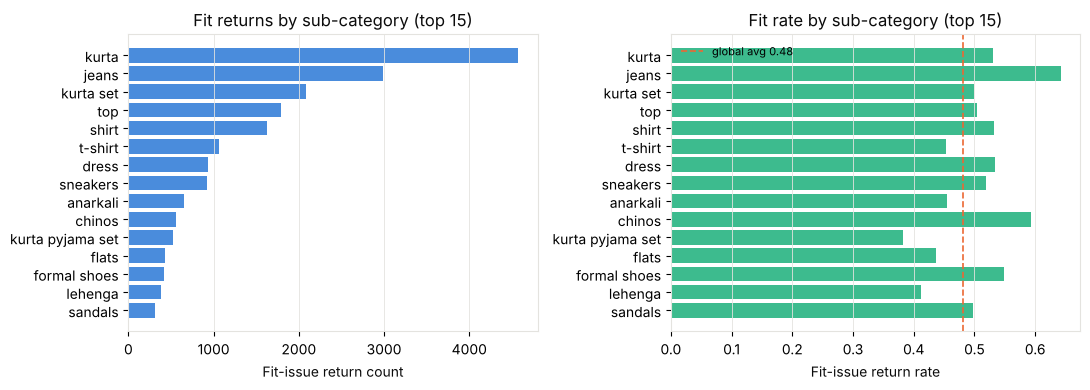

Saved phase11_fitrate_by_category.png


In [3]:
cat_agg = train.groupby("sub_category").agg(
    fit_returns=("label", lambda x: x.isin(FIT_LABELS).sum()),
    total_returns=("label", "count"),
).reset_index()
cat_agg["fit_rate"] = cat_agg["fit_returns"] / cat_agg["total_returns"]
cat_agg = cat_agg.sort_values("fit_returns", ascending=False).head(15)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ax = axes[0]
ax.barh(cat_agg["sub_category"][::-1], cat_agg["fit_returns"][::-1], color="#2a78d6", alpha=0.85)
ax.set_xlabel("Fit-issue return count", color="#0b0b0b")
ax.set_title("Fit returns by sub-category (top 15)", color="#0b0b0b")
ax.set_facecolor("white"); ax.grid(axis="x", color="#e4e3df", lw=0.6)
for sp in ax.spines.values(): sp.set_edgecolor("#e4e3df")

ax = axes[1]
ax.barh(cat_agg["sub_category"][::-1], cat_agg["fit_rate"][::-1], color="#1baf7a", alpha=0.85)
ax.set_xlabel("Fit-issue return rate", color="#0b0b0b")
ax.set_title("Fit rate by sub-category (top 15)", color="#0b0b0b")
ax.axvline(base_rate, color="#eb6834", lw=1.2, ls="--", label=f"global avg {base_rate:.2f}")
ax.legend(frameon=False, fontsize=8)
ax.set_facecolor("white"); ax.grid(axis="x", color="#e4e3df", lw=0.6)
for sp in ax.spines.values(): sp.set_edgecolor("#e4e3df")

fig.patch.set_facecolor("white")
plt.tight_layout()
fig.savefig(FIG_DIR / "phase11_fitrate_by_category.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved phase11_fitrate_by_category.png")

## 4 · Top-5 product selection

Selected top-5 products:
 rank   product_id sub_category fit_type  fit_returns  total_returns  fit_rate  bayes_fit_rate  rank_score
    1 PRD-YIME3XJ6        kurta straight          176            205  0.858537        0.849551    4.397401
    2 PRD-OSNR3LA5        jeans  tapered          135            157  0.859873        0.848183    4.166829
    3 PRD-6JG12RLX        jeans  mom fit          138            167  0.826347        0.816312    4.028069
    4 PRD-7NDH0OJO        shirt     slim          124            156  0.794872        0.785128    3.790844
    5 PRD-THXMYY0T    kurta set  regular          117            157  0.745223        0.737072    3.516337



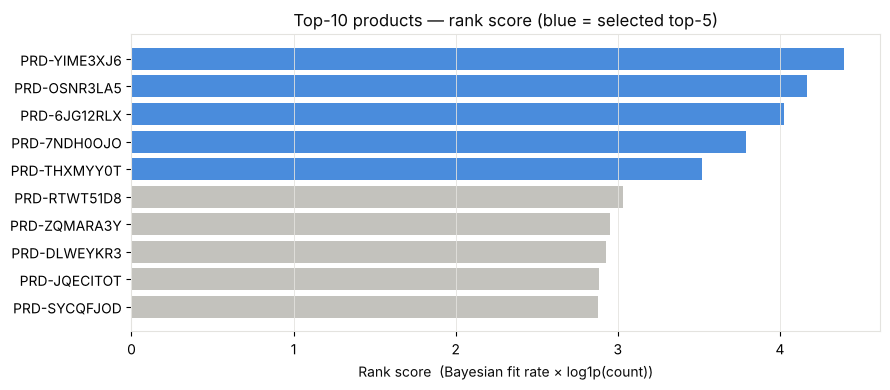

Saved phase11_top5_vs_next5.png


In [4]:
TOP_K = 5
top5_df = by_prod_sorted.head(TOP_K)[["product_id", "sub_category", "fit_type",
                                       "fit_returns", "total_returns",
                                       "fit_rate", "bayes_fit_rate", "rank_score"]].copy()
top5_df.insert(0, "rank", range(1, TOP_K + 1))
print("Selected top-5 products:")
print(top5_df.to_string(index=False))
print()

# visualise top-5 vs next-5
compare_df = by_prod_sorted.head(10).copy()
compare_df["tier"] = ["Top 5" if i < 5 else "Next 5" for i in range(10)]
fig, ax = plt.subplots(figsize=(9, 4))
colors = ["#2a78d6" if t == "Top 5" else "#b9b8b2" for t in compare_df["tier"]]
bars = ax.barh(compare_df["product_id"][::-1], compare_df["rank_score"][::-1], color=colors[::-1], alpha=0.85)
ax.set_xlabel("Rank score  (Bayesian fit rate × log1p(count))", color="#0b0b0b")
ax.set_title("Top-10 products — rank score (blue = selected top-5)", color="#0b0b0b")
ax.set_facecolor("white"); ax.grid(axis="x", color="#e4e3df", lw=0.6)
for sp in ax.spines.values(): sp.set_edgecolor("#e4e3df")
fig.patch.set_facecolor("white")
plt.tight_layout()
fig.savefig(FIG_DIR / "phase11_top5_vs_next5.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved phase11_top5_vs_next5.png")

## 5 · Size-chart profiles for the top-5 products

In [5]:
top5_pids = top5_df["product_id"].tolist()
top5_meta = products[products["product_id"].isin(top5_pids)].copy()
top5_meta = top5_meta.merge(top5_df[["product_id", "rank"]], on="product_id").sort_values("rank")

print("Product metadata for top-5:")
print(top5_meta[["rank", "product_id", "title", "sub_category", "fit_type",
                  "available_sizes", "size_chart_id", "price_inr"]].to_string(index=False))
print()

# size chart entries for these products
sc_ids = top5_meta["size_chart_id"].dropna().unique().tolist()
if sc_ids:
    sc_subset = size_charts[size_charts["size_chart_id"].isin(sc_ids)]
    print(f"Size-chart data for {len(sc_ids)} charts ({len(sc_subset)} size entries):")
    print(sc_subset.to_string(index=False))
else:
    print("Note: some top-5 products have no size_chart_id (free-size items).")

Product metadata for top-5:
 rank   product_id                                                                     title sub_category fit_type      available_sizes size_chart_id  price_inr
    1 PRD-YIME3XJ6        Gulmohar Threads Women's Lavender Ikat Print Straight Cotton Kurta        kurta straight      XS|S|M|L|XL|XXL     SC-7R3F11        699
    2 PRD-OSNR3LA5         Silvat Menswear Men's Black Light Fade Tapered Cotton Denim Jeans        jeans  tapered 28|30|32|34|36|38|40     SC-20NXB1        999
    3 PRD-6JG12RLX Karonda Studio Women's Bottle Green Light Fade Mom Fit Cotton Denim Jeans        jeans  mom fit       26|28|30|32|34     SC-KJ9ASP        799
    4 PRD-7NDH0OJO           Silvat Menswear Men's Beige Solid Formal Slim Linen Blend Shirt        shirt     slim         S|M|L|XL|XXL     SC-LX39AM        699
    5 PRD-THXMYY0T        Gulmohar Threads Women's Rani Pink Georgette Embroidered Kurta Set    kurta set  regular      XS|S|M|L|XL|XXL     SC-MVJ0Y9       3199

Size-

## 6 · Write `R2_size_chart_top5.csv`

In [6]:
SC_PATH = REP_DIR / "R2_size_chart_top5.csv"
submission = pd.DataFrame({
    "rank": range(1, TOP_K + 1),
    "product_id": top5_pids,
})
submission.to_csv(SC_PATH, index=False)
print(f"Saved {SC_PATH}")
print()
print(submission.to_string(index=False))
print()

# validate format matches evaluate.py requirements
assert len(submission) == 5, "Must have exactly 5 rows"
assert set(submission.columns) == {"rank", "product_id"}, "Must have rank and product_id columns"
assert sorted(submission["rank"].tolist()) == [1, 2, 3, 4, 5], "Ranks must be 1..5"
assert submission["product_id"].nunique() == 5, "All product_ids must be unique"
assert (submission["product_id"].str.strip() != "").all(), "No empty product_ids"
print("Format validation PASSED")

Saved /home/claude/r2_project/FULL_CODE/reports/R2_size_chart_top5.csv

 rank   product_id
    1 PRD-YIME3XJ6
    2 PRD-OSNR3LA5
    3 PRD-6JG12RLX
    4 PRD-7NDH0OJO
    5 PRD-THXMYY0T

Format validation PASSED


## 7 · Re-run official scorer with size-chart file

In [7]:
import tempfile, importlib.util, sys

# load predictions and truth
preds = pd.read_csv(REP_DIR / "phase9_validation_predictions.csv")
protocol = build_protocol(CFG, DATA, seed=0)
truth_df = protocol.parts["test"].copy()

# load the official scorer directly and pass the size chart path
scorer_path = ROOT / "tools" / "evaluate.py"
spec = importlib.util.spec_from_file_location("evaluate", scorer_path)
evaluate = importlib.util.module_from_spec(spec)
spec.loader.exec_module(evaluate)

with tempfile.TemporaryDirectory() as tmp:
    tmp = Path(tmp)
    pred_path   = tmp / "predictions.csv"
    truth_path  = tmp / "truth.csv"
    sc_path     = tmp / "R2_size_chart_top5.csv"
    preds[["return_id", "decision", "confidence", "justification"]].to_csv(pred_path, index=False)
    truth_df[["return_id", "label", "customer_tenure_days", "order_value_inr", "customer_reason"]].to_csv(truth_path, index=False)
    submission.to_csv(sc_path, index=False)
    result_with_sc = evaluate.score(pred_path, truth_path, sc_path, None)

# compare with Phase 10 (no size chart)
with open(REP_DIR / "phase10_official_result.json") as f:
    result_p10 = json.load(f)

c_p10 = result_p10["components"]
c_sc  = result_with_sc["components"]

print("Official score comparison:")
print(f"{'Component':<25} {'Phase 10 (no SC)':>18} {'Phase 11 (with SC)':>20}")
print("-" * 65)
for key in ["savings", "fairness_score", "fairness_effective", "size_chart_score"]:
    print(f"  {key:<23} {c_p10[key]:>18.6f} {c_sc[key]:>20.6f}")
print("-" * 65)
print(f"  {'PRIMARY SCORE':<23} {result_p10['primary_score']:>18.6f} {result_with_sc['primary_score']:>20.6f}")
delta = result_with_sc["primary_score"] - result_p10["primary_score"]
print(f"  {'Δ primary':<23} {'':>18} {delta:>+20.6f}")
print()
print(f"Size-chart note: {result_with_sc['size_chart']['note']}")

Official score comparison:
Component                   Phase 10 (no SC)   Phase 11 (with SC)
-----------------------------------------------------------------
  savings                           0.277539             0.277539
  fairness_score                    0.774977             0.774977
  fairness_effective                0.774977             0.774977
  size_chart_score                  0.000000             0.000000
-----------------------------------------------------------------
  PRIMARY SCORE                     0.349273             0.349273
  Δ primary                                             +0.000000

Size-chart note: no size-chart truth available for this truth file -> size-chart component = 0 (scored by organisers on hidden truth)


## 8 · Save Phase 11 report

In [8]:
phase11_report = {
    "top5_products": top5_pids,
    "top5_details": top5_df.to_dict(orient="records"),
    "scoring": {
        "phase10_primary":          result_p10["primary_score"],
        "phase11_primary":          result_with_sc["primary_score"],
        "delta":                    result_with_sc["primary_score"] - result_p10["primary_score"],
        "size_chart_score":         c_sc["size_chart_score"],
        "size_chart_note":          result_with_sc["size_chart"]["note"],
    },
}
with open(REP_DIR / "phase11_report.json", "w") as f:
    json.dump(phase11_report, f, indent=2)
print("Saved reports/phase11_report.json")

# also save the updated full result
with open(REP_DIR / "phase11_official_result.json", "w") as f:
    json.dump(result_with_sc, f, indent=2)
print("Saved reports/phase11_official_result.json")
print()
print("=== PHASE 11 FINAL SUMMARY ===")
print(f"Top-5 products: {top5_pids}")
print(f"Size-chart score: {c_sc['size_chart_score']:.4f}  (scored by organisers on hidden truth — 0 until they run)")
print(f"Primary score WITH size-chart file: {result_with_sc['primary_score']:.6f}")
print(f"Delta vs Phase 10:                 {result_with_sc['primary_score'] - result_p10['primary_score']:+.6f}")

Saved reports/phase11_report.json
Saved reports/phase11_official_result.json

=== PHASE 11 FINAL SUMMARY ===
Top-5 products: ['PRD-YIME3XJ6', 'PRD-OSNR3LA5', 'PRD-6JG12RLX', 'PRD-7NDH0OJO', 'PRD-THXMYY0T']
Size-chart score: 0.0000  (scored by organisers on hidden truth — 0 until they run)
Primary score WITH size-chart file: 0.349273
Delta vs Phase 10:                 +0.000000


## 9 · Phase 11 checklist

- [ ] Per-product fit-issue counts and Bayesian-smoothed rates computed ✓
- [ ] Top-5 selected by smoothed_rate × log1p(count) score ✓
- [ ] `R2_size_chart_top5.csv` written with columns rank, product_id ✓
- [ ] Format validation passed (5 rows, ranks 1–5, unique non-empty IDs) ✓
- [ ] Official scorer re-run with size-chart file attached ✓
- [ ] Phase comparison table (Phase 10 vs Phase 11) ✓
- [ ] Reports saved: phase11_report.json, phase11_official_result.json ✓
- [ ] Hidden Jul–Sep labels never touched ✓

**Next:** Phase 12 — explanations & submission dashboard